Tuning

In [1]:
import sys; sys.path.append("..")
import warnings; warnings.filterwarnings("ignore")
import time, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import loguniform, randint
from sklearn.model_selection import ParameterSampler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from mlflow.models import infer_signature
from src.datos import cargar_obt, metadatos_datos
from src import pipeline as P

df = P.agregar_features(cargar_obt())
train, test = P.dividir_train_test(df)
X_tr, y_tr = P.preparar_X_y(train)
META = metadatos_datos(df)
mlflow = P.configurar_mlflow()
N_CONFIGS = 30

# Resultado por defecto de cada modelo (del notebook 03, leído desde MLflow)
exp = mlflow.get_experiment_by_name("merma-cerveza")
cand = mlflow.search_runs([exp.experiment_id], filter_string="tags.fase = 'candidato'")
DEFECTO = {r["tags.mlflow.runName"]: (r["metrics.cv_roc_auc_media"], r["metrics.cv_roc_auc_std"]) for _, r in cand.iterrows()}

# Espacios de búsqueda: escala logarítmica para parámetros que varían en órdenes de magnitud
ESPACIOS = {
    "logistica": (LogisticRegression, "lineal_regularizado", {
        "C": loguniform(1e-3, 1e2),
        "penalty": ["l1", "l2"],
        "class_weight": [None, "balanced"],
        "solver": ["liblinear"], "max_iter": [2000], "random_state": [P.SEMILLA],
    }),
    "random_forest": (RandomForestClassifier, "bagging", {
        "n_estimators": randint(100, 501),
        "max_depth": [2, 3, 4, 6, 8, None],
        "min_samples_leaf": randint(1, 21),
        "max_features": ["sqrt", "log2", 0.5, None],
        "class_weight": [None, "balanced"],
        "random_state": [P.SEMILLA], "n_jobs": [-1],
    }),
    "mlp": (MLPClassifier, "red_neuronal", {
        "hidden_layer_sizes": [(4,), (8,), (16,), (32,), (8, 4), (16, 8)],
        "alpha": loguniform(1e-5, 1e1),
        "learning_rate_init": loguniform(1e-4, 1e-1),
        "max_iter": [2000], "random_state": [P.SEMILLA],
    }),
}
for nombre in ESPACIOS:
    print(f"{nombre:15s} defecto ROC-AUC {DEFECTO[nombre][0]:.3f} ± {DEFECTO[nombre][1]:.3f}")

logistica       defecto ROC-AUC 0.629 ± 0.152
random_forest   defecto ROC-AUC 0.632 ± 0.143
mlp             defecto ROC-AUC 0.604 ± 0.138


Mejor configuracion 

In [2]:
todos, resumen = [], []

for nombre, (Clase, familia, espacio) in ESPACIOS.items():
    configs = list(ParameterSampler(espacio, n_iter=N_CONFIGS, random_state=P.SEMILLA))
    t0 = time.time()
    with mlflow.start_run(run_name=f"tuning_{nombre}") as padre:          # corrida PADRE por modelo
        hijos = []
        for i, cfg in enumerate(configs, 1):                              # 30 corridas HIJAS
            run_id, met, _ = P.evaluar_y_registrar(
                f"{nombre}_cfg{i:02d}", Clase(**cfg), X_tr, y_tr, "tuning", familia, META,
                    nested=True, guardar_modelo=True, params_extra={k: str(v) for k, v in cfg.items()})
            hijos.append({"config": i, "run_id": run_id, **{k: str(v) for k, v in cfg.items()}, **met})
        hijos = pd.DataFrame(hijos)
        todos.append(hijos.assign(modelo=nombre))

        # Mejor configuración (mayor ROC-AUC en CV) y comparación con el modelo por defecto
        mejor = hijos.loc[hijos["cv_roc_auc_media"].idxmax()]
        cfg_mejor = configs[int(mejor["config"]) - 1]
        def_media, def_std = DEFECTO[nombre]
        mejora = float(mejor["cv_roc_auc_media"] - def_media)

        pipe = P.construir_pipeline(Clase(**cfg_mejor)).fit(X_tr, y_tr)
        cols_met = [c for c in hijos.columns if c.startswith(("cv_", "train_")) or c in ("brecha", "segundos_entrenamiento")]
        mlflow.log_params({f"mejor_{k}": str(v) for k, v in cfg_mejor.items()}
                          | {"n_configs": N_CONFIGS, "busqueda": "aleatoria (ParameterSampler)", "semilla": P.SEMILLA, **META})
        mlflow.log_metrics({c: float(mejor[c]) for c in cols_met}
                           | {"mejora_vs_defecto": mejora, "cv_roc_auc_defecto": def_media, "segundos_tuning": time.time() - t0})
        mlflow.set_tags({"fase": "tuning", "familia": familia, "tipo": "padre", "commit_git": P.commit_git(),
                         "esquema_cv": "TimeSeriesSplit(5)", "mejor_run_hijo": mejor["run_id"]})
        mlflow.sklearn.log_model(pipe, "modelo", signature=infer_signature(X_tr, pipe.predict(X_tr)),
                                 input_example=X_tr.dropna().head(5))

    resumen.append({"modelo": nombre, "run_id_padre": padre.info.run_id,
                    "roc_auc_defecto": def_media, "std_defecto": def_std,
                    "roc_auc_tuning": mejor["cv_roc_auc_media"], "std_tuning": mejor["cv_roc_auc_std"],
                    "mejora": mejora, "mejora_real": abs(mejora) > def_std,
                    "brecha_tuning": mejor["brecha"], "costo_tuning": mejor["cv_costo_media"],
                    "minutos": (time.time() - t0) / 60})
    print(f"{nombre}: defecto {def_media:.3f} → tuning {mejor['cv_roc_auc_media']:.3f} ± {mejor['cv_roc_auc_std']:.3f} "
          f"(mejora {mejora:+.3f}; ¿supera la desviación? {abs(mejora) > def_std}) | brecha {mejor['brecha']:.3f}")

resumen = pd.DataFrame(resumen).set_index("modelo")
todos = pd.concat(todos, ignore_index=True)
todos.to_csv("../docs/resultados_tuning.csv", index=False)
resumen.round(3)

2026/11/18 15:26:11 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


2026/11/18 15:26:12 INFO mlflow.tracking._tracking_service.client: 🏃 View run logistica_cfg01 at: http://localhost:5050/#/experiments/1/runs/cf8186c8e6bd44bda454e75c1e539c72.
2026/11/18 15:26:12 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://localhost:5050/#/experiments/1.
2026/11/18 15:26:20 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


2026/11/18 15:26:21 INFO mlflow.tracking._tracking_service.client: 🏃 View run logistica_cfg02 at: http://localhost:5050/#/experiments/1/runs/ab596284350f4350aab1cd9f5c83f233.
2026/11/18 15:26:21 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://localhost:5050/#/experiments/1.
2026/11/18 15:26:27 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


2026/11/18 15:26:27 INFO mlflow.tracking._tracking_service.client: 🏃 View run logistica_cfg03 at: http://localhost:5050/#/experiments/1/runs/8b5b260d812b4b598a8ddc4a62f621eb.
2026/11/18 15:26:27 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://localhost:5050/#/experiments/1.
2026/11/18 15:26:32 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


2026/11/18 15:26:32 INFO mlflow.tracking._tracking_service.client: 🏃 View run logistica_cfg04 at: http://localhost:5050/#/experiments/1/runs/eb9b5232e8f649c19eda53361fbc5d73.
2026/11/18 15:26:32 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://localhost:5050/#/experiments/1.
2026/11/18 15:26:37 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


2026/11/18 15:26:37 INFO mlflow.tracking._tracking_service.client: 🏃 View run logistica_cfg05 at: http://localhost:5050/#/experiments/1/runs/91423cc00c174d3588591ef6e842b25b.
2026/11/18 15:26:37 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://localhost:5050/#/experiments/1.
2026/11/18 15:26:42 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


... (90 outputs left out)

2026/11/18 15:37:56 INFO mlflow.tracking._tracking_service.client: 🏃 View run mlp_cfg30 at: http://localhost:5050/#/experiments/1/runs/14a83ae554fb49b99358642e4d4024a0.
2026/11/18 15:37:56 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://localhost:5050/#/experiments/1.
2026/11/18 15:38:01 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


2026/11/18 15:38:01 INFO mlflow.tracking._tracking_service.client: 🏃 View run tuning_mlp at: http://localhost:5050/#/experiments/1/runs/98541bb7d28e4bf9bec8cf445b0e3e7f.
2026/11/18 15:38:01 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://localhost:5050/#/experiments/1.


mlp: defecto 0.604 → tuning 0.664 ± 0.143 (mejora +0.059; ¿supera la desviación? False) | brecha 0.037


,run_id_padre,roc_auc_defecto,std_defecto,roc_auc_tuning,std_tuning,mejora,mejora_real,brecha_tuning,costo_tuning,minutos
modelo,,,,,,,,,,
logistica,50220710ff9b468099abd9ca6cd218c0,0.629,0.152,0.635,0.123,0.006,False,-0.038,30.734,2.808
random_forest,51e12d31977143fd89642a4298a02cb6,0.632,0.143,0.629,0.143,-0.002,False,0.359,23.060,5.020
mlp,98541bb7d28e4bf9bec8cf445b0e3e7f,0.604,0.138,0.664,0.143,0.059,False,0.037,32.495,4.146


Graficos 

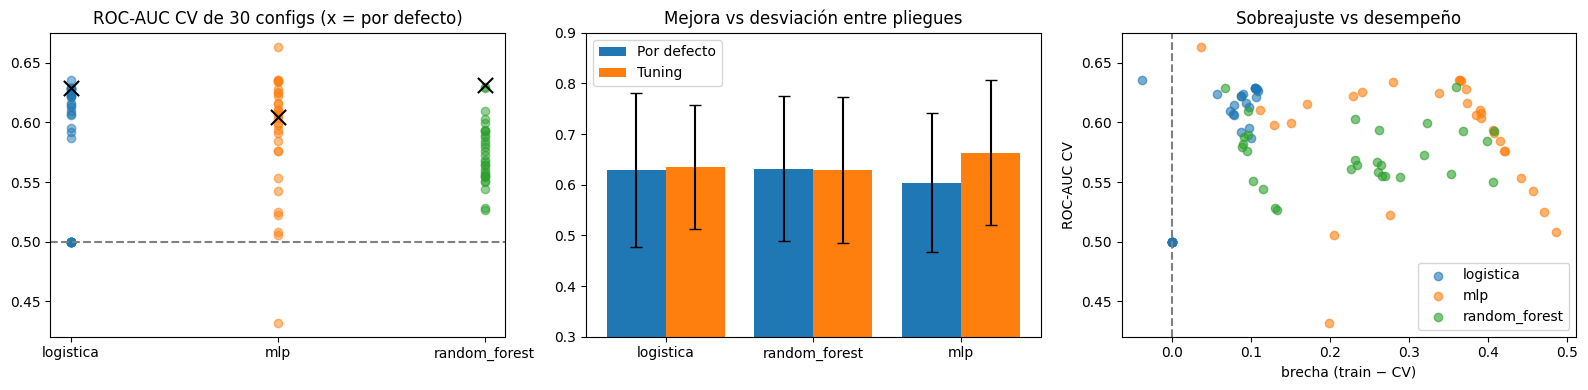

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

# 1) ROC-AUC de las 30 configuraciones por modelo vs su valor por defecto
for i, (nombre, g) in enumerate(todos.groupby("modelo")):
    ax[0].scatter([i] * len(g), g["cv_roc_auc_media"], alpha=0.5)
    ax[0].scatter(i, DEFECTO[nombre][0], marker="x", s=120, color="black")
ax[0].set_xticks(range(todos["modelo"].nunique()), sorted(todos["modelo"].unique()))
ax[0].axhline(0.5, ls="--", color="gray"); ax[0].set_title("ROC-AUC CV de 30 configs (x = por defecto)")

# 2) Defecto vs mejor configuración, con la desviación entre pliegues
x = np.arange(len(resumen))
ax[1].bar(x - 0.2, resumen["roc_auc_defecto"], 0.4, yerr=resumen["std_defecto"], label="Por defecto", capsize=4)
ax[1].bar(x + 0.2, resumen["roc_auc_tuning"], 0.4, yerr=resumen["std_tuning"], label="Tuning", capsize=4)
ax[1].set_xticks(x, resumen.index); ax[1].set_ylim(0.3, 0.9); ax[1].legend(); ax[1].set_title("Mejora vs desviación entre pliegues")

# 3) Sobreajuste: brecha entrenamiento - CV de cada configuración
for i, (nombre, g) in enumerate(todos.groupby("modelo")):
    ax[2].scatter(g["brecha"], g["cv_roc_auc_media"], alpha=0.6, label=nombre)
ax[2].axvline(0, ls="--", color="gray"); ax[2].set_xlabel("brecha (train − CV)"); ax[2].set_ylabel("ROC-AUC CV")
ax[2].legend(); ax[2].set_title("Sobreajuste vs desempeño")

plt.tight_layout(); plt.savefig("../docs/figs/07_tuning.png", dpi=150); plt.show()